# 04. Optimización de hiperparámetros y análisis de sensibilidad

Aplicación del Workshop 2 de la Semana 5 (*Análisis de sensibilidad de hiperparámetros*) a las ramas del
detector que admiten una búsqueda con presupuesto razonable.

**Pregunta guía:** ¿qué hiperparámetros merecen presupuesto de búsqueda y cuáles se pueden fijar?

**Método (igual al del workshop):**

1. Búsqueda bayesiana con Optuna (TPE, semilla fija) usando validación cruzada **solo sobre entrenamiento**.
2. Análisis de las pruebas con tres herramientas: importancia de hiperparámetros (fANOVA), efecto individual
   (`plot_slice` y *partial dependence* con un modelo sustituto) y efectos de interacción (contorno y
   dependencia parcial en 2D).
3. Comparación antes y después con validación cruzada repetida, intervalo de confianza por bootstrap y prueba de
   Wilcoxon sobre los pliegues pareados. La partición de prueba se usa una sola vez, al final.

| Estudio | Modelo | Métrica objetivo | Validación cruzada |
|---|---|---|---|
| A | Rama URL (XGBoost) | Precisión promedio (AUC-PR) de phishing | 5 pliegues agrupados por dominio |
| B | Línea base (TF-IDF y regresión logística) | F1 macro | 3 pliegues estratificados sobre una muestra de entrenamiento |

**Criterio de adopción, fijado antes de mirar los resultados:** la configuración optimizada reemplaza a la
actual solo si el límite inferior del intervalo de confianza al 95 % de la mejora es mayor que cero. Una
diferencia que cae dentro del intervalo no justifica cambiar un modelo ya desplegado y medido de punta a punta.

**DistilBERT no se optimiza aquí.** Cada ajuste fino cuesta unos 13 minutos de GPU T4 en la partición
principal (3 épocas de 4 a 5 minutos, `results/metrics/distilbert_v1_principal.json`), por lo que 60 pruebas
superarían las 13 horas. Se usaron los valores
estándar de ajuste fino (tasa 5e-5, 3 épocas, calentamiento del 10 %) con parada temprana, y la regularización
se diagnosticó en la Semana 3 (`notebooks/experimentos/16_diagnostico_sobreajuste`).

In [17]:
# Rutas, semillas y módulos del proyecto. En Colab se monta Google Drive: el repositorio
# debe estar copiado en MyDrive/PI_G17/phishing-hibrido-g17 y los datos en MyDrive/PI_G17.
# Las variables de entorno G17_REPO y G17_BASE permiten usar otras ubicaciones.
import os
import sys
from pathlib import Path

try:
    from google.colab import drive

    drive.mount("/content/drive")
    RAIZ_POR_DEFECTO = "/content/drive/MyDrive/PI_G17/phishing-hibrido-g17"
except ImportError:
    RAIZ_POR_DEFECTO = str(Path.cwd().parent)

RAIZ = Path(os.environ.get("G17_REPO", RAIZ_POR_DEFECTO)).resolve()
if not (RAIZ / "src").is_dir():
    raise FileNotFoundError(f"No se encontró el repositorio en {RAIZ}; defina G17_REPO")
sys.path.insert(0, str(RAIZ))

from src.utils import cargar_config, configurar_logging, detectar_entorno, fijar_semillas, ruta_datos
from src.visualizacion import aplicar_estilo, guardar_figura

CONFIG = cargar_config(RAIZ / "config.yaml")
SEMILLA = CONFIG["semilla"]
fijar_semillas(SEMILLA)
configurar_logging("WARNING")
aplicar_estilo()

ENTORNO = detectar_entorno()
BASE = ruta_datos(CONFIG, ENTORNO)
PROCESADOS = BASE / CONFIG["rutas"]["datos_procesados"]
MODELOS = BASE / CONFIG["rutas"]["modelos"]
FIGURAS = RAIZ / "results/figures/04_optimizacion"
METRICAS = RAIZ / "results/metrics"
FIGURAS.mkdir(parents=True, exist_ok=True)
METRICAS.mkdir(parents=True, exist_ok=True)
print(f"Entorno: {ENTORNO} | repositorio: {RAIZ} | datos: {BASE}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Entorno: colab | repositorio: /content/drive/MyDrive/PI_G17/phishing-hibrido-g17 | datos: /content/drive/MyDrive/PI_G17


In [18]:
import importlib.util
import json
import subprocess
import time
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")
if importlib.util.find_spec("optuna") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "optuna==5.0.0"], check=True)

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import xgboost as xgb
from optuna.importance import FanovaImportanceEvaluator
from optuna.visualization.matplotlib import plot_contour, plot_optimization_history, plot_param_importances, plot_slice
from scipy.stats import wilcoxon
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.inspection import PartialDependenceDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.pipeline import FeatureUnion, Pipeline

from src import train
from src.visualizacion import COLORES_SERIE

warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
PARAMETROS = CONFIG["optimizacion"]
print("optuna", optuna.__version__, "| xgboost", xgb.__version__)

optuna 5.0.0 | xgboost 3.4.1


In [19]:
def bootstrap_media(diferencias, remuestreos=2000):
    """Intervalo de confianza al 95 % de la media de las diferencias pareadas, por bootstrap."""
    generador = np.random.default_rng(SEMILLA)
    medias = [generador.choice(diferencias, len(diferencias)).mean() for _ in range(remuestreos)]
    return [float(v) for v in np.percentile(medias, [2.5, 97.5])]


def comparar_pareado(puntajes_antes, puntajes_despues):
    """Resumen de la comparación antes/después sobre los mismos pliegues."""
    antes, despues = np.asarray(puntajes_antes), np.asarray(puntajes_despues)
    diferencias = despues - antes
    inferior, superior = bootstrap_media(diferencias)
    prueba = wilcoxon(despues, antes) if np.any(diferencias != 0) else None
    return {
        "antes_media": round(float(antes.mean()), 5), "antes_desv": round(float(antes.std()), 5),
        "despues_media": round(float(despues.mean()), 5), "despues_desv": round(float(despues.std()), 5),
        "mejora_media": round(float(diferencias.mean()), 5),
        "ic95_mejora": [round(inferior, 5), round(superior, 5)],
        "wilcoxon_p": None if prueba is None else round(float(prueba.pvalue), 5),
        "adoptar": bool(inferior > 0),
    }


def restaurar_estilo():
    # Las funciones de Optuna cambian el estilo global de matplotlib (ggplot); se vuelve al del proyecto.
    plt.style.use("default")
    aplicar_estilo()


def traducir_leyenda(eje):
    nombres = {"Objective Value": "Puntaje de la prueba", "Best Value": "Mejor hasta el momento"}
    leyenda = eje.get_legend()
    if leyenda is not None:
        for texto in leyenda.get_texts():
            texto.set_text(nombres.get(texto.get_text(), texto.get_text()))


def figura_sensibilidad(estudio, prefijo, titulo, numero, metrica):
    """Historial, importancia, slice, dependencia parcial e interacción de un estudio de Optuna."""
    pruebas = estudio.trials_dataframe(attrs=("params", "value", "state"))
    pruebas = pruebas[pruebas["state"] == "COMPLETE"]
    rango = pruebas["value"].agg(["min", "median", "max"]).round(5).to_dict()
    if pruebas["value"].nunique() < 2:
        print("Todas las pruebas obtuvieron el mismo puntaje: no hay variación que atribuir a los hiperparámetros.")
        return {}, rango, pruebas
    evaluador = FanovaImportanceEvaluator(seed=SEMILLA)
    importancias = optuna.importance.get_param_importances(estudio, evaluator=evaluador)

    eje = plot_optimization_history(estudio)
    eje.figure.set_size_inches(7, 3.4)
    eje.set_title(f"Figura {numero}a. {titulo}: historial de la búsqueda")
    eje.set_xlabel("Prueba")
    eje.set_ylabel(metrica)
    traducir_leyenda(eje)
    guardar_figura(eje.figure, FIGURAS / f"{prefijo}_historial.png")
    plt.show()

    eje = plot_param_importances(estudio, evaluator=evaluador)
    eje.figure.set_size_inches(7, 3.2)
    eje.set_title(f"Figura {numero}b. {titulo}: importancia de hiperparámetros (fANOVA)", loc="left")
    eje.set_xlabel("Importancia relativa")
    eje.set_ylabel("")
    if eje.get_legend() is not None:
        eje.get_legend().remove()
    guardar_figura(eje.figure, FIGURAS / f"{prefijo}_importancia.png")
    plt.show()

    ejes = np.ravel(plot_slice(estudio))
    ejes[0].set_ylabel(metrica)
    ejes[0].figure.set_size_inches(3.2 * len(ejes), 3.4)
    ejes[0].figure.suptitle(f"Figura {numero}c. {titulo}: puntaje de cada prueba por hiperparámetro",
                            fontweight="bold", fontsize=11)
    guardar_figura(ejes[0].figure, FIGURAS / f"{prefijo}_slice.png")
    plt.show()
    restaurar_estilo()

    # Dependencia parcial con un modelo sustituto que predice el puntaje a partir de los hiperparámetros
    columnas = [c for c in pruebas.columns if c.startswith("params_")]
    X_sustituto = pruebas[columnas].astype(float).rename(columns=lambda c: c.replace("params_", ""))
    sustituto = RandomForestRegressor(n_estimators=300, random_state=SEMILLA).fit(X_sustituto, pruebas["value"])
    figura, ejes = plt.subplots(1, len(columnas), figsize=(3.2 * len(columnas), 3.4), sharey=True)
    PartialDependenceDisplay.from_estimator(sustituto, X_sustituto, features=list(X_sustituto.columns),
                                            ax=np.ravel(ejes), line_kw={"color": COLORES_SERIE[0]})
    for k, eje in enumerate(np.ravel(ejes)):
        eje.set_ylabel(f"{metrica} esperado" if k == 0 else "")
    figura.suptitle(f"Figura {numero}d. {titulo}: dependencia parcial (modelo sustituto)",
                    fontweight="bold", fontsize=11)
    guardar_figura(figura, FIGURAS / f"{prefijo}_dependencia_parcial.png")
    plt.show()

    # Interacción entre los dos hiperparámetros más importantes
    principales = list(importancias)[:2]
    eje = plot_contour(estudio, params=principales)
    eje.figure.set_size_inches(6.2, 4.4)
    eje.set_title(f"Figura {numero}e. {titulo}: interacción {principales[0]} x {principales[1]}")
    guardar_figura(eje.figure, FIGURAS / f"{prefijo}_contorno.png")
    plt.show()
    restaurar_estilo()

    figura, eje = plt.subplots(figsize=(5.2, 4.2))
    PartialDependenceDisplay.from_estimator(sustituto, X_sustituto, features=[tuple(principales)], ax=eje)
    figura.suptitle(f"Figura {numero}f. {titulo}: dependencia parcial 2D ({metrica} esperado)",
                    fontweight="bold", fontsize=11)
    guardar_figura(figura, FIGURAS / f"{prefijo}_dependencia_2d.png")
    plt.show()

    return {k: round(float(v), 4) for k, v in importancias.items()}, rango, pruebas

## Estudio A. Rama URL (XGBoost)

### A.1 Datos de la búsqueda

Una fila por URL de correo (hasta 20 por correo), con la etiqueta débil heredada del correo. Para respetar el
diseño de la rama, el entrenamiento excluye todo dominio presente en validación o prueba, y los pliegues de la
búsqueda se agrupan por dominio: ningún dominio aparece a la vez en el ajuste y en la evaluación de un pliegue.

In [20]:
datos = pd.read_parquet(PROCESADOS / "emails_v1.parquet", columns=["id", "clase", "y", "split", "urls_defang"])
categorias_tld = json.loads((MODELOS / "url_xgb_v1.meta.json").read_text())["tld_categorias"]
urls, variables = train.tabla_urls(datos, CONFIG["rama_url"]["max_urls_por_correo"])
X_urls = train.matriz_url(variables, categorias_tld)
dominios_evaluacion = set(urls.loc[urls["split"].isin(["val", "test"]), "dominio"])
en_entrenamiento = ((urls["split"] == "train") & ~urls["dominio"].isin(dominios_evaluacion)).to_numpy()

X_busqueda = X_urls[en_entrenamiento].reset_index(drop=True)
y_busqueda = urls.loc[en_entrenamiento, "y"].to_numpy()
grupos = urls.loc[en_entrenamiento, "dominio"].to_numpy()
print(f"URL de entrenamiento: {len(X_busqueda):,} | dominios: {len(set(grupos)):,} | "
      f"phishing: {y_busqueda.mean():.1%}")

URL de entrenamiento: 10,001 | dominios: 4,577 | phishing: 46.3%


### A.2 Configuración actual y espacio de búsqueda

La configuración actual es la publicada: `config.yaml` con el número de árboles que eligió la parada temprana
(`mejor_iteracion + 1` en `results/metrics/rama_url_v1.json`).

| Hiperparámetro | Rango | Escala | Actual |
|---|---|---|---|
| `max_depth` | 2 a 12 | entera | 6 |
| `learning_rate` | 0,01 a 0,3 | logarítmica | 0,05 |
| `n_estimators` | 100 a 1.000 | entera, paso 50 | según parada temprana |
| `min_child_weight` | 1 a 20 | logarítmica | 1 |
| `subsample` | 0,5 a 1,0 | lineal | 0,8 |
| `colsample_bytree` | 0,5 a 1,0 | lineal | 0,8 |
| `reg_lambda` | 0,001 a 10 | logarítmica | 1 |

In [21]:
rama_url_publicada = json.loads((METRICAS / "rama_url_v1.json").read_text())
ACTUAL_URL = {k: v for k, v in CONFIG["rama_url"]["xgboost"].items() if k != "early_stopping_rounds"}
ACTUAL_URL.update({"n_estimators": rama_url_publicada["M6_variante_correos"]["mejor_iteracion"] + 1,
                   "min_child_weight": 1.0, "reg_lambda": 1.0})


def modelo_url(parametros):
    return xgb.XGBClassifier(**parametros, tree_method="hist", enable_categorical=True,
                             random_state=SEMILLA, n_jobs=-1)


def cv_url(parametros, semilla=SEMILLA):
    """AUC-PR de cada pliegue, con pliegues estratificados y agrupados por dominio."""
    pliegues = StratifiedGroupKFold(n_splits=PARAMETROS["rama_url"]["n_folds"], shuffle=True, random_state=semilla)
    puntajes = []
    for indices_ajuste, indices_prueba in pliegues.split(X_busqueda, y_busqueda, grupos):
        modelo = modelo_url(parametros).fit(X_busqueda.iloc[indices_ajuste], y_busqueda[indices_ajuste])
        puntaje = modelo.predict_proba(X_busqueda.iloc[indices_prueba])[:, 1]
        puntajes.append(average_precision_score(y_busqueda[indices_prueba], puntaje))
    return puntajes


def objetivo_url(prueba):
    parametros = {
        "max_depth": prueba.suggest_int("max_depth", 2, 12),
        "learning_rate": prueba.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "n_estimators": prueba.suggest_int("n_estimators", 100, 1000, step=50),
        "min_child_weight": prueba.suggest_float("min_child_weight", 1.0, 20.0, log=True),
        "subsample": prueba.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": prueba.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_lambda": prueba.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
    }
    return float(np.mean(cv_url(parametros)))


inicio = time.time()
puntaje_actual_url = float(np.mean(cv_url(ACTUAL_URL)))
print(f"Configuración actual: AUC-PR en validación cruzada {puntaje_actual_url:.4f} "
      f"({time.time() - inicio:.0f} s por evaluación)")

Configuración actual: AUC-PR en validación cruzada 0.8757 (6 s por evaluación)


### A.3 Búsqueda con Optuna

In [22]:
estudio_url = optuna.create_study(direction="maximize", study_name="rama_url",
                                  sampler=optuna.samplers.TPESampler(seed=SEMILLA))
inicio = time.time()
estudio_url.optimize(objetivo_url, n_trials=PARAMETROS["rama_url"]["n_trials"],
                     timeout=PARAMETROS["rama_url"]["timeout_s"])
print(f"Pruebas completadas: {len(estudio_url.trials)} en {(time.time() - inicio) / 60:.1f} min")
print(f"Mejor AUC-PR: {estudio_url.best_value:.4f} | actual: {puntaje_actual_url:.4f}")
estudio_url.best_params

Pruebas completadas: 60 en 6.3 min
Mejor AUC-PR: 0.8783 | actual: 0.8757


{'max_depth': 5,
 'learning_rate': 0.047196616386832035,
 'n_estimators': 300,
 'min_child_weight': 1.0535763308112676,
 'subsample': 0.878704398352192,
 'colsample_bytree': 0.8049383840228588,
 'reg_lambda': 0.3790081323558767}

### A.4 Análisis de sensibilidad

Al leer las figuras conviene mirar la escala del eje vertical: si todas las pruebas quedan en un rango estrecho,
el modelo es poco sensible a sus hiperparámetros y la configuración actual ya está en la meseta.

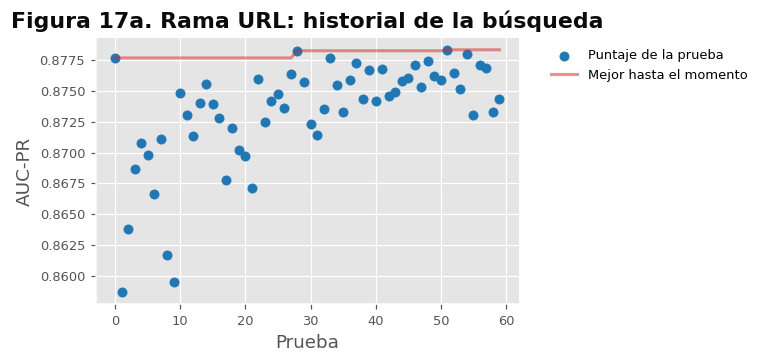

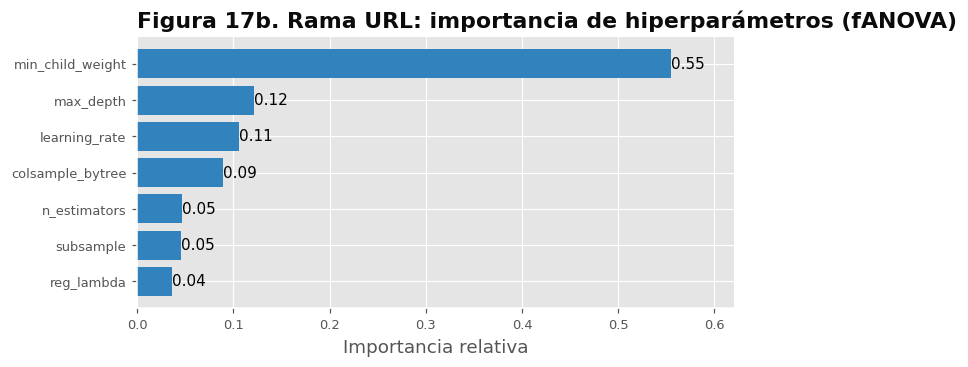

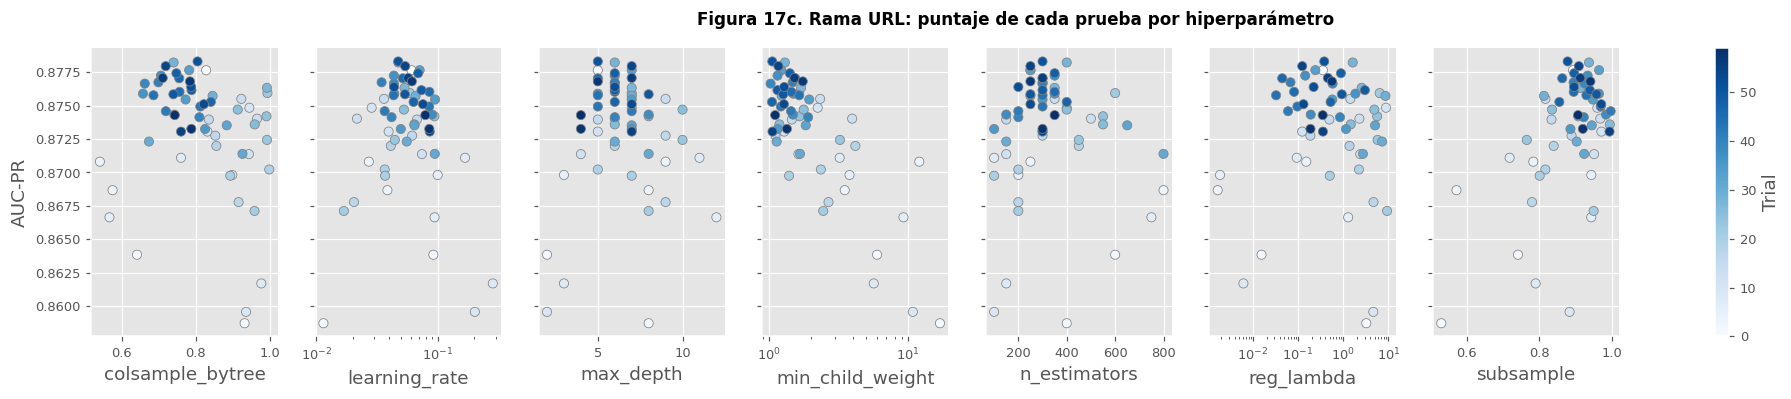

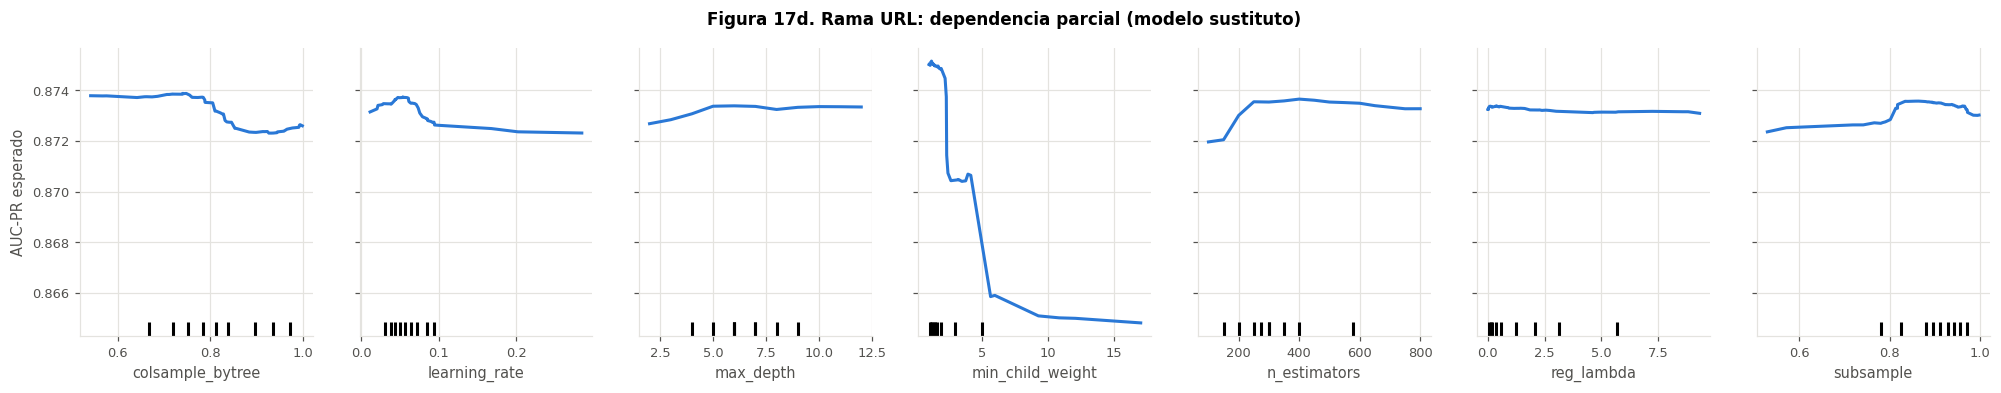

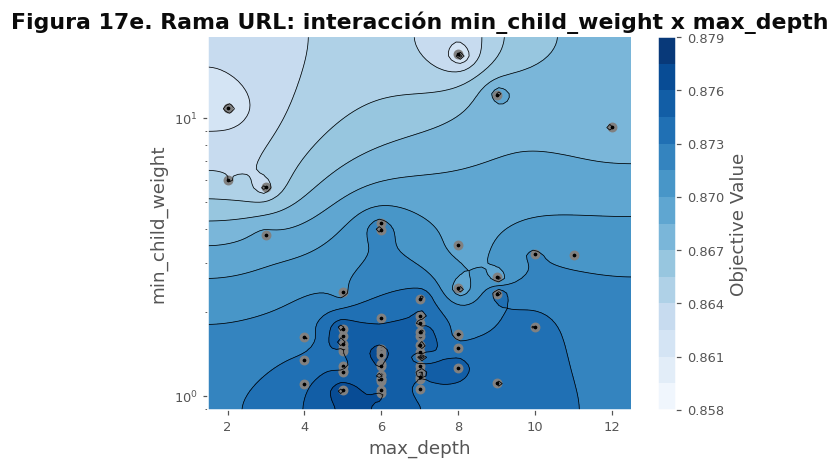

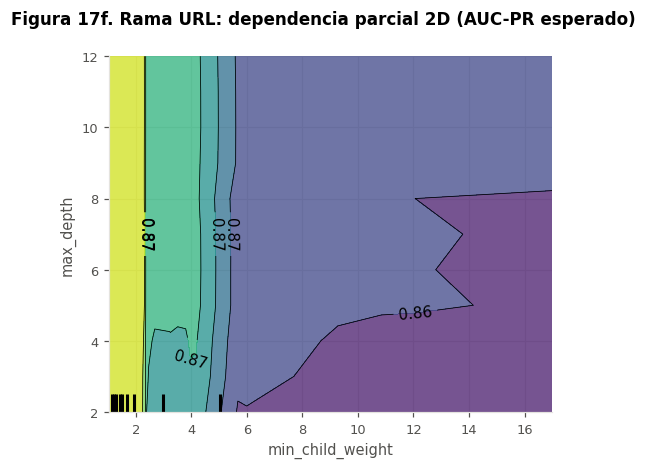

Importancia: {'min_child_weight': 0.5548, 'max_depth': 0.1219, 'learning_rate': 0.1057, 'colsample_bytree': 0.0896, 'n_estimators': 0.0463, 'subsample': 0.0452, 'reg_lambda': 0.0365}
Rango del AUC-PR entre pruebas: {'min': 0.85872, 'median': 0.87431, 'max': 0.87831}


In [23]:
importancia_url, rango_url, pruebas_url = figura_sensibilidad(estudio_url, "fig17_url", "Rama URL", 17, "AUC-PR")
print("Importancia:", importancia_url)
print("Rango del AUC-PR entre pruebas:", rango_url)

**Lectura del estudio A.** El AUC-PR de las 60 pruebas va de 0,859 a 0,878: menos de dos puntos entre la peor y
la mejor configuración, y la mediana (0,874) queda a 0,4 puntos del máximo. El ranking de importancia es:

| Hiperparámetro | Importancia (fANOVA) | Efecto (figuras 17c y 17d) |
|---|---|---|
| `min_child_weight` | 0,55 | Los mejores valores están cerca de 1; el puntaje cae de forma marcada por encima de 2 |
| `max_depth` | 0,12 | Efecto pequeño; profundidades de 4 a 7 rinden igual |
| `learning_rate` | 0,11 | Plano entre 0,02 y 0,1 |
| `colsample_bytree` | 0,09 | Plano |
| `n_estimators`, `subsample`, `reg_lambda` | 0,05 o menos | Sin efecto práctico: se pueden fijar |

En el contorno y en la dependencia parcial 2D (figuras 17e y 17f) las curvas de nivel son casi verticales en
`min_child_weight`: el efecto de `max_depth` es pequeño para cualquier valor de `min_child_weight`, así que no se
observa una interacción relevante entre ambos. La configuración actual (`min_child_weight` = 1, profundidad 6,
tasa 0,05) ya está en la meseta.

### A.5 Comparación antes y después

Ambas configuraciones se evalúan sobre los mismos pliegues en 3 repeticiones con semillas distintas
(15 pares). Se reporta la mejora media, su intervalo bootstrap al 95 % y la prueba de Wilcoxon.

In [24]:
mejor_url = {**estudio_url.best_params}
antes_url, despues_url = [], []
for repeticion in range(PARAMETROS["rama_url"]["repeticiones_comparacion"]):
    antes_url += cv_url(ACTUAL_URL, semilla=SEMILLA + repeticion)
    despues_url += cv_url(mejor_url, semilla=SEMILLA + repeticion)
comparacion_url = comparar_pareado(antes_url, despues_url)
comparacion_url

{'antes_media': 0.87655,
 'antes_desv': 0.01759,
 'despues_media': 0.87725,
 'despues_desv': 0.01917,
 'mejora_media': 0.00069,
 'ic95_mejora': [-0.00152, 0.0029],
 'wilcoxon_p': 0.63867,
 'adoptar': False}

La configuración optimizada mejora el AUC-PR medio en 0,0007, con intervalo al 95 % de -0,0015 a 0,0029 y
Wilcoxon p = 0,64 sobre 15 pliegues pareados. La diferencia es mucho menor que la variación entre pliegues
(desviación de 0,018): según el criterio fijado, se mantiene la configuración actual.

### A.6 Prueba final (una sola vez)

Ambas configuraciones se ajustan con todas las URL de entrenamiento y se evalúan por correo en la partición de
prueba: el puntaje del correo es el máximo de sus URL, y se mide phishing frente al resto entre los correos que
tienen URL.

In [25]:
en_prueba = (urls["split"] == "test").to_numpy()
etiqueta_correo = datos.set_index("id")["y"].eq(2).astype(int)


def evaluar_en_prueba(parametros):
    modelo = modelo_url(parametros).fit(X_busqueda, y_busqueda)
    puntajes = pd.Series(modelo.predict_proba(X_urls[en_prueba])[:, 1], index=urls.index[en_prueba])
    por_correo = puntajes.groupby(urls.loc[en_prueba, "id"]).max()
    y = etiqueta_correo.loc[por_correo.index].to_numpy()
    return {"auc_roc": round(float(roc_auc_score(y, por_correo)), 4),
            "auc_pr": round(float(average_precision_score(y, por_correo)), 4),
            "correos": int(len(y))}


prueba_url = {"actual": evaluar_en_prueba(ACTUAL_URL), "optimizada": evaluar_en_prueba(mejor_url)}
pd.DataFrame(prueba_url).T

,auc_roc,auc_pr,correos
actual,0.8830,0.7773,5736.0
optimizada,0.8735,0.7724,5736.0


En la prueba, la configuración actual queda incluso por encima (AUC-ROC 0,883 frente a 0,874; AUC-PR 0,777 frente
a 0,772). Es el efecto esperable de elegir la mejor de 60 pruebas sobre la misma validación cruzada: parte de su
ventaja era ruido, y desaparece en datos nuevos.

## Estudio B. Línea base de texto (TF-IDF y regresión logística)

Ajustar el pipeline completo sobre los 38.278 correos de entrenamiento toma entre dos y tres minutos, de modo que la
búsqueda se hace sobre una muestra estratificada por clase y corpus, con 3 pliegues. Las conclusiones sobre
sensibilidad son válidas en esa escala; la configuración actual también se evalúa sobre la misma muestra.

| Hiperparámetro | Rango | Actual |
|---|---|---|
| `C` | 0,05 a 50 (logarítmica) | 8 |
| `max_features` de palabras | 5.000 a 100.000 (logarítmica) | 100.000 |
| `ngram_max` de palabras | 1 o 2 | 2 |
| `min_df` de palabras | 1 a 10 | 3 |
| `caracteres` (agregar n-gramas de caracteres 3-5) | sí o no | sí |

In [26]:
textos = pd.read_parquet(PROCESADOS / "emails_v1.parquet", columns=["clase", "grupo", "y", "split", "texto_modelo"])
textos = textos[textos["split"] == "train"]
fraccion = min(1.0, PARAMETROS["baseline"]["muestra_train"] / len(textos))
muestra = textos.groupby(["clase", "grupo"]).sample(frac=fraccion, random_state=SEMILLA)
X_texto = muestra["texto_modelo"].str[: CONFIG["texto"]["max_chars_baseline"]].to_numpy()
y_texto = muestra["y"].to_numpy()
print(f"Muestra de entrenamiento: {len(muestra):,} correos", muestra["clase"].value_counts().to_dict())

ACTUAL_TEXTO = {"C": 8.0, "max_features": 100_000, "ngram_max": 2, "min_df": 3, "caracteres": True}


def pipeline_texto(parametros):
    palabras = TfidfVectorizer(ngram_range=(1, parametros["ngram_max"]), min_df=parametros["min_df"], max_df=0.9,
                               max_features=parametros["max_features"], sublinear_tf=True)
    partes = [("palabras", palabras)]
    if parametros["caracteres"]:
        partes.append(("caracteres", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=5,
                                                     max_features=100_000, sublinear_tf=True)))
    clasificador = LogisticRegression(C=parametros["C"], max_iter=2000, class_weight="balanced")
    return Pipeline([("tfidf", FeatureUnion(partes)), ("lr", clasificador)])


def cv_texto(parametros, semilla=SEMILLA):
    pliegues = StratifiedKFold(n_splits=PARAMETROS["baseline"]["n_folds"], shuffle=True, random_state=semilla)
    puntajes = []
    for indices_ajuste, indices_prueba in pliegues.split(X_texto, y_texto):
        modelo = pipeline_texto(parametros).fit(X_texto[indices_ajuste], y_texto[indices_ajuste])
        puntajes.append(f1_score(y_texto[indices_prueba], modelo.predict(X_texto[indices_prueba]), average="macro"))
    return puntajes


def objetivo_texto(prueba):
    parametros = {
        "C": prueba.suggest_float("C", 0.05, 50.0, log=True),
        "max_features": prueba.suggest_int("max_features", 5_000, 100_000, log=True),
        "ngram_max": prueba.suggest_int("ngram_max", 1, 2),
        "min_df": prueba.suggest_int("min_df", 1, 10),
        "caracteres": prueba.suggest_categorical("caracteres", [True, False]),
    }
    return float(np.mean(cv_texto(parametros)))


inicio = time.time()
puntaje_actual_texto = float(np.mean(cv_texto(ACTUAL_TEXTO)))
print(f"Configuración actual: F1 macro en validación cruzada {puntaje_actual_texto:.4f} "
      f"({time.time() - inicio:.0f} s por evaluación)")

Muestra de entrenamiento: 6,000 correos {'spam': 2566, 'legitimo': 2346, 'phishing': 1088}
Configuración actual: F1 macro en validación cruzada 0.9694 (78 s por evaluación)


In [11]:
estudio_texto = optuna.create_study(direction="maximize", study_name="baseline",
                                    sampler=optuna.samplers.TPESampler(seed=SEMILLA))
inicio = time.time()
estudio_texto.optimize(objetivo_texto, n_trials=PARAMETROS["baseline"]["n_trials"],
                       timeout=PARAMETROS["baseline"]["timeout_s"])
print(f"Pruebas completadas: {len(estudio_texto.trials)} en {(time.time() - inicio) / 60:.1f} min")
print(f"Mejor F1 macro: {estudio_texto.best_value:.4f} | actual: {puntaje_actual_texto:.4f}")
estudio_texto.best_params

Pruebas completadas: 27 en 25.7 min
Mejor F1 macro: 0.9705 | actual: 0.9694


{'C': 39.836422717353734,
 'max_features': 20518,
 'ngram_max': 2,
 'min_df': 5,
 'caracteres': True}

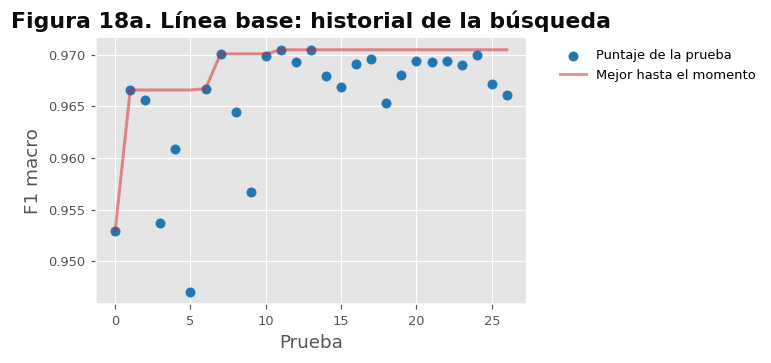

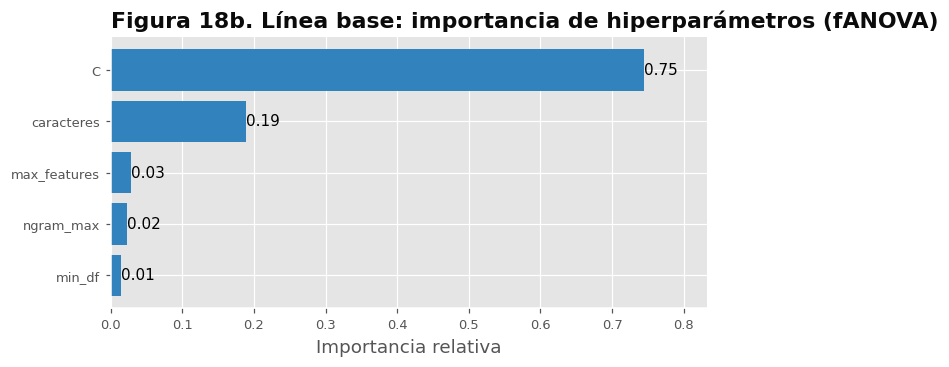

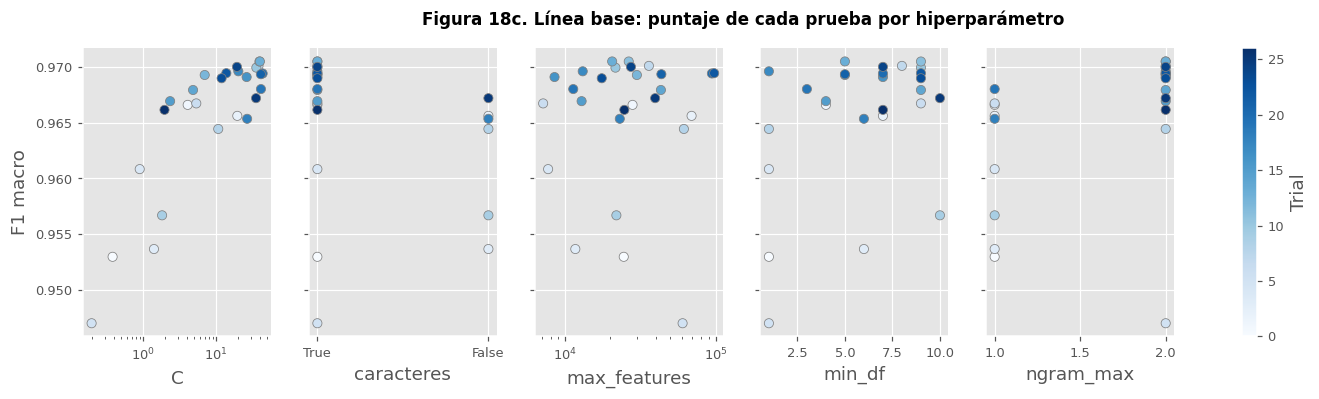

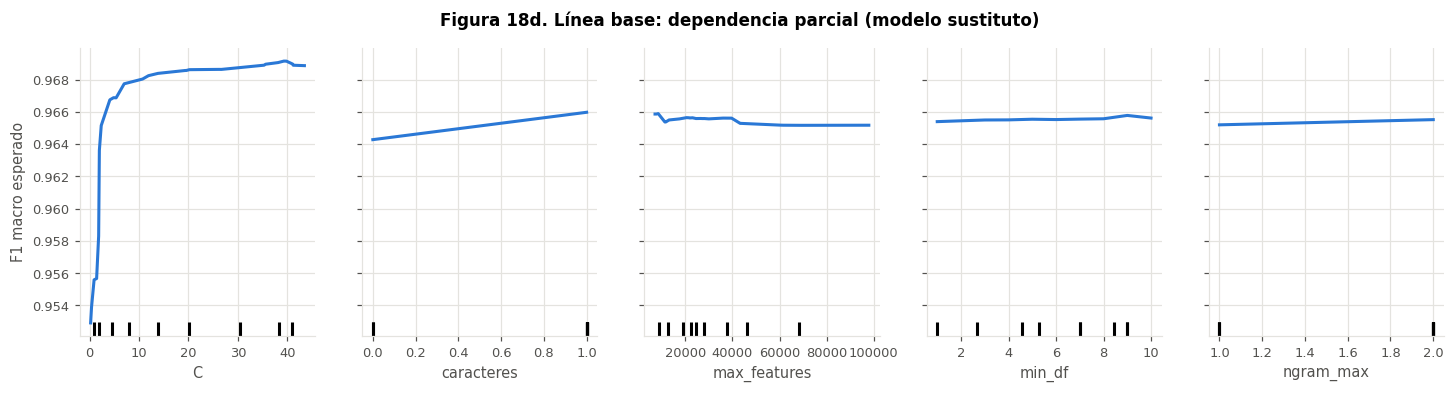

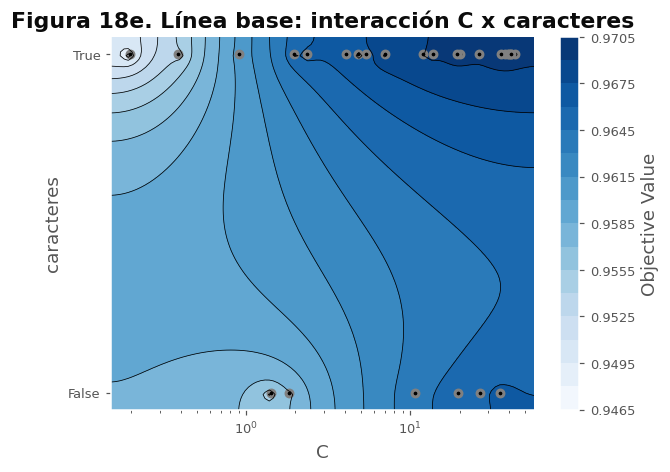

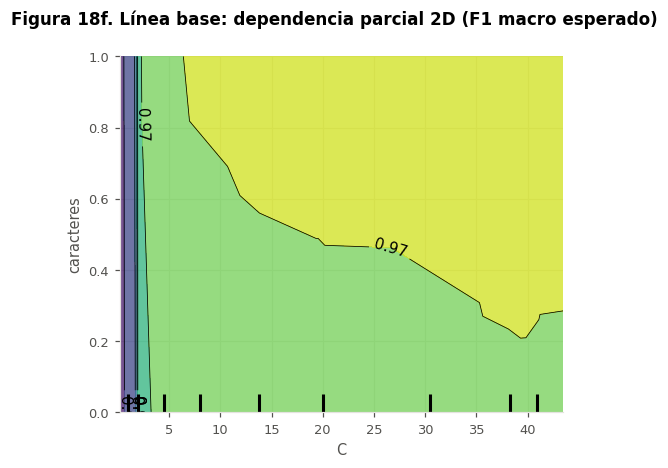

Importancia: {'C': 0.7452, 'caracteres': 0.1887, 'max_features': 0.0289, 'ngram_max': 0.0233, 'min_df': 0.0139}
Rango del F1 macro entre pruebas: {'min': 0.94703, 'median': 0.96793, 'max': 0.97049}


In [12]:
importancia_texto, rango_texto, pruebas_texto = figura_sensibilidad(estudio_texto, "fig18_baseline",
                                                                    "Línea base", 18, "F1 macro")
print("Importancia:", importancia_texto)
print("Rango del F1 macro entre pruebas:", rango_texto)

**Lectura del estudio B.** La búsqueda completó 27 de las 30 pruebas antes del límite de tiempo. El F1 macro va
de 0,947 a 0,970, y el ranking de importancia es:

| Hiperparámetro | Importancia (fANOVA) | Efecto (figuras 18c y 18d) |
|---|---|---|
| `C` | 0,75 | Con C menor que 3 el F1 cae de forma marcada; por encima de 10 se estabiliza |
| `caracteres` | 0,19 | Agregar n-gramas de caracteres suma unas dos milésimas |
| `max_features`, `ngram_max`, `min_df` | 0,03 o menos | Sin efecto práctico |

La dependencia parcial 2D de C y `caracteres` (figura 18f) muestra una interacción leve: la ventaja de los
n-gramas de caracteres aparece cuando C es mayor que 3 a 5, y con C bajo ambas opciones rinden mal. El valor
actual (C = 8, con caracteres) está en la meseta. Para una búsqueda futura convendría ampliar C hacia arriba y
fijar el resto.

In [13]:
mejor_texto = {**estudio_texto.best_params}
antes_texto, despues_texto = [], []
for repeticion in range(2):
    antes_texto += cv_texto(ACTUAL_TEXTO, semilla=SEMILLA + repeticion)
    despues_texto += cv_texto(mejor_texto, semilla=SEMILLA + repeticion)
comparacion_texto = comparar_pareado(antes_texto, despues_texto)
comparacion_texto

{'antes_media': 0.96888,
 'antes_desv': 0.00271,
 'despues_media': 0.96974,
 'despues_desv': 0.00347,
 'mejora_media': 0.00085,
 'ic95_mejora': [-0.00052, 0.00226],
 'wilcoxon_p': 0.5625,
 'adoptar': False}

La mejora es de 0,0009 en F1 macro, con intervalo de -0,0005 a 0,0023 y Wilcoxon p = 0,56 sobre 6 pliegues
pareados: se mantiene la configuración actual.

## Comparación antes y después

**Figura 19.** Puntaje por pliegue de la configuración actual y de la optimizada en cada estudio. Cada línea
une el mismo pliegue evaluado con ambas configuraciones.

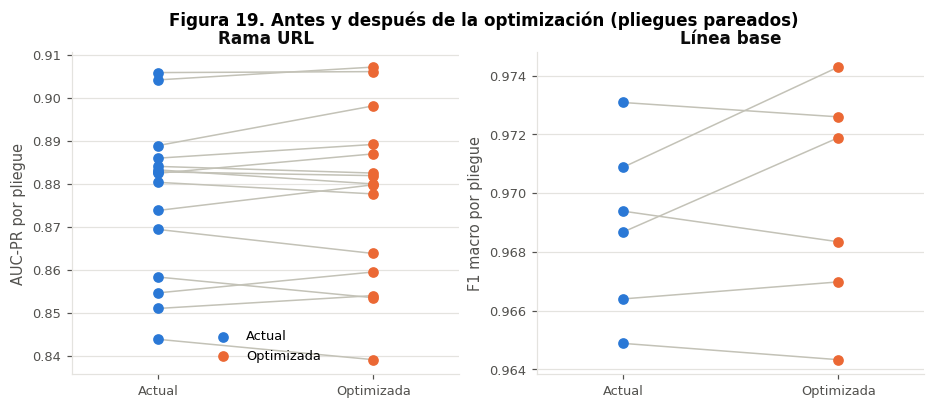

,antes_media,despues_media,mejora_media,ic95_mejora,wilcoxon_p,adoptar
Rama URL (AUC-PR),0.87655,0.87725,0.00069,"[-0.00152, 0.0029]",0.63867,False
Línea base (F1 macro),0.96888,0.96974,0.00085,"[-0.00052, 0.00226]",0.5625,False


In [14]:
figura, ejes = plt.subplots(1, 2, figsize=(10, 3.8))
for eje, (titulo, antes, despues, metrica) in zip(ejes, [
        ("Rama URL", antes_url, despues_url, "AUC-PR"),
        ("Línea base", antes_texto, despues_texto, "F1 macro")], strict=True):
    for a, d in zip(antes, despues, strict=True):
        eje.plot([0, 1], [a, d], color="#c3c2b7", linewidth=1)
    eje.scatter(np.zeros(len(antes)), antes, color=COLORES_SERIE[0], zorder=3, label="Actual")
    eje.scatter(np.ones(len(despues)), despues, color=COLORES_SERIE[1], zorder=3, label="Optimizada")
    eje.set_xticks([0, 1], ["Actual", "Optimizada"])
    eje.set_xlim(-0.4, 1.4)
    eje.set_ylabel(f"{metrica} por pliegue")
    eje.set_title(titulo)
    eje.grid(axis="x", visible=False)
ejes[0].legend(loc="lower center")
figura.suptitle("Figura 19. Antes y después de la optimización (pliegues pareados)", fontweight="bold",
                fontsize=11)
guardar_figura(figura, FIGURAS / "fig19_antes_despues.png")
plt.show()

tabla_final = pd.DataFrame({
    "Rama URL (AUC-PR)": comparacion_url,
    "Línea base (F1 macro)": comparacion_texto,
}).T[["antes_media", "despues_media", "mejora_media", "ic95_mejora", "wilcoxon_p", "adoptar"]]
tabla_final

## Configuración final y justificación

La decisión se toma con el criterio fijado al inicio. La celda siguiente la deja registrada con sus números.

In [15]:
def decision(nombre, comparacion, actual, mejor):
    if comparacion["adoptar"]:
        return (f"{nombre}: la mejora es significativa (IC95 {comparacion['ic95_mejora']}). Se documenta la "
                f"configuración optimizada {mejor} para la siguiente versión del modelo; la versión desplegada "
                "(v2) no cambia, porque los KPI de integración se midieron con ella.")
    return (f"{nombre}: el intervalo de la mejora {comparacion['ic95_mejora']} incluye el cero o es negativo. "
            f"Se mantiene la configuración actual {actual}.")


decisiones = [decision("Rama URL", comparacion_url, ACTUAL_URL, mejor_url),
              decision("Línea base", comparacion_texto, ACTUAL_TEXTO, mejor_texto)]
for texto in decisiones:
    print("-", texto)

- Rama URL: el intervalo de la mejora [-0.00152, 0.0029] incluye el cero o es negativo. Se mantiene la configuración actual {'n_estimators': 334, 'learning_rate': 0.05, 'max_depth': 6, 'subsample': 0.8, 'colsample_bytree': 0.8, 'min_child_weight': 1.0, 'reg_lambda': 1.0}.
- Línea base: el intervalo de la mejora [-0.00052, 0.00226] incluye el cero o es negativo. Se mantiene la configuración actual {'C': 8.0, 'max_features': 100000, 'ngram_max': 2, 'min_df': 3, 'caracteres': True}.


## Conclusiones

1. **Qué importa y qué se puede fijar.** En la rama URL solo `min_child_weight` mueve el resultado de forma
   apreciable; en la línea base, la regularización (C) y, en menor medida, los n-gramas de caracteres. El resto de
   los hiperparámetros se puede fijar sin pérdida.
2. **Interacciones.** No hay interacción relevante en la rama URL y hay una leve en la línea base (los n-gramas de
   caracteres ayudan solo con C suficientemente alto).
3. **Rangos.** Ambas configuraciones actuales están en la zona plana de la respuesta; la búsqueda no encontró una
   región mejor dentro de rangos amplios.
4. **Por qué no se cambia.** Las mejoras encontradas (0,0007 y 0,0009) son menores que la variación entre pliegues
   y sus intervalos incluyen el cero. Elegir la configuración con el mejor puntaje entre decenas de pruebas
   sobrestima su ventaja, como confirma la prueba de la rama URL. Cambiar un modelo ya desplegado y medido de
   punta a punta por una diferencia de ese tamaño no se justifica.

La configuración final es la publicada en la versión v2 y registrada en `config.yaml`.

In [16]:
pruebas_url.to_csv(METRICAS / "optimizacion_pruebas_url.csv", index=False)
pruebas_texto.to_csv(METRICAS / "optimizacion_pruebas_baseline.csv", index=False)
resumen = {
    "rama_url": {
        "n_pruebas": len(estudio_url.trials), "actual": ACTUAL_URL, "puntaje_cv_actual": round(puntaje_actual_url, 5),
        "mejor": mejor_url, "puntaje_cv_mejor": round(estudio_url.best_value, 5), "importancia": importancia_url,
        "rango_entre_pruebas": rango_url, "comparacion": comparacion_url, "prueba_final": prueba_url},
    "baseline": {
        "n_pruebas": len(estudio_texto.trials), "muestra": int(len(muestra)), "actual": ACTUAL_TEXTO,
        "puntaje_cv_actual": round(puntaje_actual_texto, 5), "mejor": mejor_texto,
        "puntaje_cv_mejor": round(estudio_texto.best_value, 5), "importancia": importancia_texto,
        "rango_entre_pruebas": rango_texto, "comparacion": comparacion_texto},
    "decisiones": decisiones,
}
(METRICAS / "optimizacion_resumen.json").write_text(json.dumps(resumen, indent=1, ensure_ascii=False, default=str),
                                                    encoding="utf-8")
print(json.dumps({k: {c: resumen[k][c] for c in ("importancia", "comparacion")} for k in ("rama_url", "baseline")},
                 indent=1, ensure_ascii=False, default=str))

{
 "rama_url": {
  "importancia": {
   "min_child_weight": 0.5548,
   "max_depth": 0.1219,
   "learning_rate": 0.1057,
   "colsample_bytree": 0.0896,
   "n_estimators": 0.0463,
   "subsample": 0.0452,
   "reg_lambda": 0.0365
  },
  "comparacion": {
   "antes_media": 0.87655,
   "antes_desv": 0.01759,
   "despues_media": 0.87725,
   "despues_desv": 0.01917,
   "mejora_media": 0.00069,
   "ic95_mejora": [
    -0.00152,
    0.0029
   ],
   "wilcoxon_p": 0.63867,
   "adoptar": false
  }
 },
 "baseline": {
  "importancia": {
   "C": 0.7452,
   "caracteres": 0.1887,
   "max_features": 0.0289,
   "ngram_max": 0.0233,
   "min_df": 0.0139
  },
  "comparacion": {
   "antes_media": 0.96888,
   "antes_desv": 0.00271,
   "despues_media": 0.96974,
   "despues_desv": 0.00347,
   "mejora_media": 0.00085,
   "ic95_mejora": [
    -0.00052,
    0.00226
   ],
   "wilcoxon_p": 0.5625,
   "adoptar": false
  }
 }
}
